# 04 training evaluation

In [1]:
from pathlib import Path

import pandas as pd

import classification
from classification.model_config import MODEL_CONFIGS
from classification.training import create_models, create_cross_validation, compare_models, tune_model

## Baseline and evaluation metrics

In [2]:
df = pd.read_csv("../data/raw/student_mental_health.csv")

In [3]:
from classification.model_config import RANDOM_STATE
from sklearn.model_selection import train_test_split
from classification.preprocessing import remove_invalid_targets

cleaned_df = remove_invalid_targets(df)
X = cleaned_df.drop(columns=["Student_ID", "Mental_Health_Risk"])

risk_codes = {"Low": 0, "Medium": 1, "High": 2}
y = cleaned_df["Mental_Health_Risk"].map(risk_codes)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)


models = create_models(MODEL_CONFIGS)
cv = create_cross_validation()
result = compare_models(models, X_train, y_train, cv)


/usr/local/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedC

In [4]:
display(result)

,model,mean_score,std_score,mean_fit_time
0,logistic_regression,0.757750,0.019044,0.278520
3,svc,0.720679,0.022225,0.718588
2,random_forest,0.680571,0.019407,0.629707
1,decision_tree,0.578059,0.012181,0.150952


In [5]:

best = result.iloc[0]["model"]
best_2 = result.iloc[1]["model"]
search_best_1 = tune_model(models[best], MODEL_CONFIGS[best]["search_space"],
                           X_train,
                           y_train,
                           cv,
                           method="grid")

search_best_2 = tune_model(models[best_2], MODEL_CONFIGS[best_2]["search_space"], X_train, y_train, cv, method="grid")

/usr/local/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedC

In [6]:
from pathlib import Path
import joblib

model_path = Path("../reports/models/champion.joblib")
model_path_2 = Path("../reports/models/champion2.joblib")
model_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(search_best_1.best_estimator_, model_path)
joblib.dump(search_best_2.best_estimator_, model_path_2)

['../reports/models/champion2.joblib']

Accuracy: 0.7675
              precision    recall  f1-score   support

         Low      0.831     0.780     0.805       132
      Medium      0.645     0.674     0.659       132
        High      0.833     0.846     0.839       136

    accuracy                          0.767       400
   macro avg      0.770     0.767     0.768       400
weighted avg      0.770     0.767     0.769       400

Matrice de confusion (lignes=vrai, colonnes=prédit):
file saved in:  /workspace/reports/figures/confusion_matrix_LogisticRegression.png


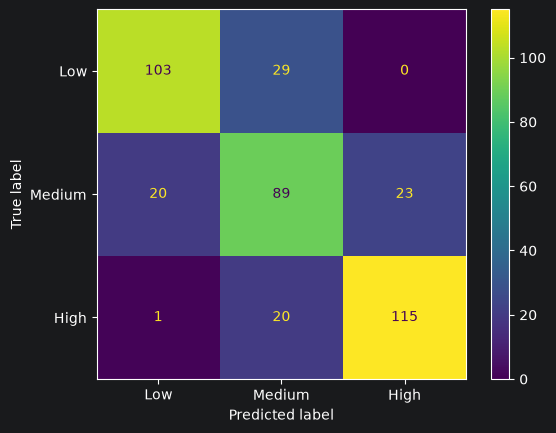

Accuracy: 0.7475
              precision    recall  f1-score   support

         Low      0.820     0.758     0.787       132
      Medium      0.620     0.644     0.632       132
        High      0.809     0.838     0.823       136

    accuracy                          0.748       400
   macro avg      0.750     0.747     0.747       400
weighted avg      0.750     0.748     0.748       400

Matrice de confusion (lignes=vrai, colonnes=prédit):
file saved in:  /workspace/reports/figures/confusion_matrix_SVC.png


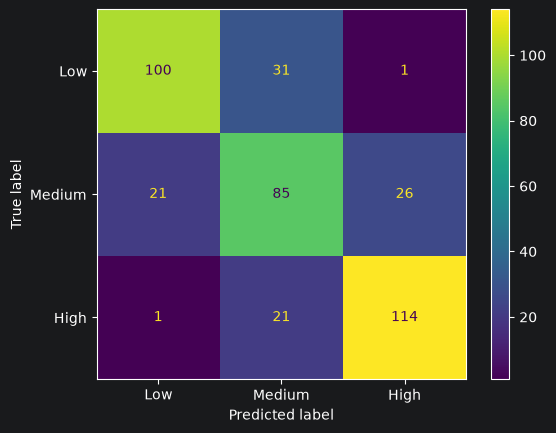

file saved in:  /workspace/reports/figures/roc_auc_graph_LogisticRegression.png


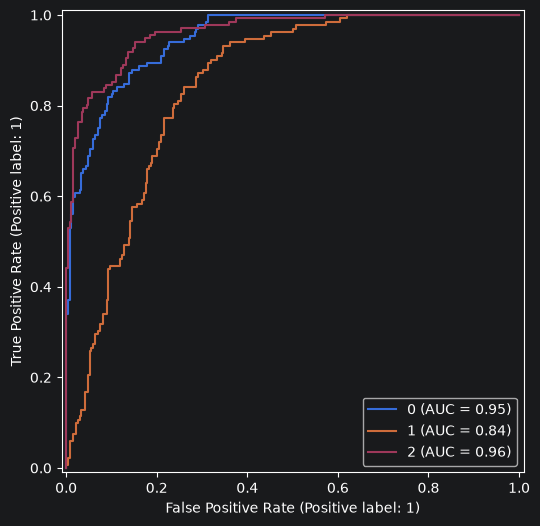

In [8]:
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, roc_auc_score, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay
from classification.plotting import save_figure

model = joblib.load(model_path)
model_name1 = type(model.named_steps["model"]).__name__
model2 = joblib.load(model_path_2)
model_name2 = type(model2.named_steps["model"]).__name__
y_pred = model.predict(X_test)
y2_pred = model2.predict(X_test)
labels = [0, 1, 2]
names = ["Low", "Medium", "High"]

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, labels=labels, target_names=names, digits=3))
print("Matrice de confusion (lignes=vrai, colonnes=prédit):")
conf_matrix = confusion_matrix(y_test, y_pred, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix= conf_matrix, display_labels = names)
disp.plot()
save_figure(disp.figure_, f"confusion_matrix_{model_name1}")
plt.show()

print("Accuracy:", accuracy_score(y_test, y2_pred))
print(classification_report(y_test, y2_pred, labels=labels, target_names=names, digits=3))
print("Matrice de confusion (lignes=vrai, colonnes=prédit):")
conf_matrix = confusion_matrix(y_test, y2_pred, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix= conf_matrix, display_labels = names)
disp.plot()

save_figure(disp.figure_, f"confusion_matrix_{model_name2}")
plt.show()






proba = model.predict_proba(X_test)
fig, ax = plt.subplots(figsize=(7, 6))
for column, label in enumerate(model.classes_):
    RocCurveDisplay.from_predictions(
        y_test == label,
        proba[:, column],
        name= str(label),
        ax=ax
    )
save_figure(fig, f"roc_auc_graph_{model_name1}")
plt.show()





we can see that the model with the best result is Logistic regression according to F1 score , in both steps first experiment and after tuning the best two models ( ll, svc ) , but we dont have a good result f1 = 0.768 , the problem is within the medium class , according to the confusiong matrix we had a 89 true prediction from 132 on test data   , therefor its f1 score = 0.659 also its auc = 0.84  which represent the area of medium